# 4. Ablaciones y comparación: ¿qué aporta la parte cuántica?

v3 es un modelo híbrido: una capa clásica de entrada, un circuito y una capa clásica de salida. Que el conjunto alcance cierta accuracy no dice cuánto de ella se debe al circuito; las capas clásicas podrían estar haciendo la mayor parte del trabajo. Este notebook lo mide quitando o fijando partes de v3 y comparando con controles clásicos.

El protocolo (datos, optimizador, semillas, métrica) es el del notebook 01.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from qcnn_mnist import figuras
from qcnn_mnist import resultados as res

figuras.aplicar_estilo()
R = res.cargar()   # modelo -> resultados por semilla (results/<modelo>/semilla_<s>.json)
S = res.resumen(R) # modelo -> media y desviación entre semillas

## Las ablaciones

| Modelo | Qué se cambia respecto de v3 | Qué mide |
| --- | --- | --- |
| **v3 con circuito congelado** | Los parámetros del circuito se inicializan con la semilla y no se entrenan; solo se entrenan la capa de entrada y la de salida | Cuánto aporta entrenar el circuito frente a un circuito aleatorio |
| **v3 solo clásico** | Sin circuito: cada parche aporta $\cos\theta$ (el ⟨Z⟩ que daría su qubit justo después de la codificación) y una capa lineal 16 → 10 clasifica | Cuánto resuelven las capas clásicas solas |
| **v3 en campo medio** | El mismo circuito simulado como estado producto, con cada CNOT sustituida por una rotación condicionada al valor esperado del control (detalle abajo) | Cuánto aporta el entrelazamiento si se conserva el flujo de información entre qubits |
| **v3 sin interacción entre qubits** | Se quitan todas las compuertas de dos qubits: los anillos de CNOT y las CNOT del pooling. Las rotaciones se mantienen | Cuánto aporta que los qubits interactúen (ver la nota abajo) |

**Nota sobre "sin interacción entre qubits".** Sin compuertas de dos qubits, cada qubit evoluciona por separado y el ⟨Z⟩ de un qubit medido depende solo de su propio parche. Los 4 qubits que se miden corresponden a los parches 3, 7, 11 y 15, la columna derecha de la rejilla. Por eso esta ablación no mide solo la ausencia de entrelazamiento: mide un modelo que **ve 4 de los 16 parches**.

**Campo medio.** Para separar el entrelazamiento del flujo de información, el circuito de v3 se simula como un producto de estados de un qubit: el estado de 16 qubits es siempre $|\psi_0\rangle \otimes \dots \otimes |\psi_{15}\rangle$, así que no puede haber correlaciones cuánticas. Las compuertas de un qubit son exactamente las de v3, con los mismos parámetros y la misma codificación. Cada CNOT(c, t), incluidas las del pooling, se sustituye por

$$R_X\big(\pi\, p_1(c)\big) \text{ sobre } t, \qquad p_1(c) = \frac{1 - \langle Z_c \rangle}{2},$$

calculado en ese punto del circuito: invierte $t$ en la proporción en que $c$ está en $|1\rangle$. Si $c$ está en $|0\rangle$ no hace nada y si está en $|1\rangle$ actúa como una NOT, igual que la CNOT; en los casos intermedios, en lugar de entrelazar los dos qubits, rota el objetivo según el promedio del control. La lectura (⟨Z⟩ de los mismos 4 qubits), la cabeza lineal y el conteo de parámetros (180) son los de v3. Las pruebas verifican que el estado sigue siendo producto, que las compuertas coinciden con las de PennyLane y que con entradas de la base computacional da lo mismo que el circuito cuántico.

La celda siguiente cambia un parche cada vez y comprueba si cambia la salida de cada modelo:

In [2]:
from qcnn_mnist.datos import preparar_datos
from qcnn_mnist.modelos import construir_modelo

x = preparar_datos(16).x_test[:20]
for nombre in ["v3_sin_entrelazamiento", "v3_campo_medio"]:
    modelo = construir_modelo(nombre)
    entrenables, fijos = res.cargar_parametros(nombre, 42)
    base = np.asarray(modelo.salida(entrenables, fijos, x))
    rng = np.random.default_rng(0)
    influyen = []
    for k in range(16):
        f, c = divmod(k, 4)
        x2 = np.array(x)
        x2[:, 4 * f : 4 * f + 4, 4 * c : 4 * c + 4] = rng.random((len(x), 4, 4))
        if np.abs(np.asarray(modelo.salida(entrenables, fijos, x2)) - base).max() > 1e-9:
            influyen.append(k)
    print(f"Parches que cambian la salida de {res.NOMBRES[nombre]}: {influyen}")

Parches que cambian la salida de v3 sin interacción entre qubits: [3, 7, 11, 15]


Parches que cambian la salida de v3 en campo medio: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


## Resultados de todos los modelos

In [3]:
display(Markdown(res.tabla_markdown(S, res.ORDEN)))

| Modelo | Parámetros | Accuracy de prueba (%) | Accuracy de entrenamiento (%) | Cómputo (h) |
| --- | ---: | ---: | ---: | ---: |
| QCNN v1 | 26 | 15,1 ± 10,7 | 15,3 ± 10,4 | 0,06 |
| QCNN v2 | 64 | 23,1 ± 4,6 | 22,2 ± 4,3 | 0,07 |
| v2 con lectura ⟨Z⟩ | 114 | 44,7 ± 2,3 | 45,7 ± 2,9 | 0,09 |
| QCNN v3 | 180 | 43,3 ± 3,0 | 45,7 ± 1,9 | 5,43 |
| v3 con circuito congelado | 84 | 26,2 ± 2,0 | 26,5 ± 4,0 | 4,05 |
| v3 solo clásico | 204 | 68,1 ± 4,1 | 70,3 ± 0,6 | 0,01 |
| v3 en campo medio | 180 | 39,1 ± 3,9 | 40,3 ± 2,8 | 0,03 |
| v3 sin interacción entre qubits | 180 | 32,9 ± 0,8 | 33,3 ± 0,5 | 4,53 |
| CNN 10×10 | 225 | 59,9 ± 4,4 | 60,9 ± 4,3 | 0,01 |
| CPN 10×10 | 78 | 46,9 ± 0,8 | 46,9 ± 1,3 | 0,01 |
| CNN 16×16 | 459 | 77,1 ± 1,6 | 83,0 ± 1,7 | 0,01 |
| CPN 16×16 | 112 | 61,0 ± 5,0 | 60,4 ± 5,9 | 0,01 |

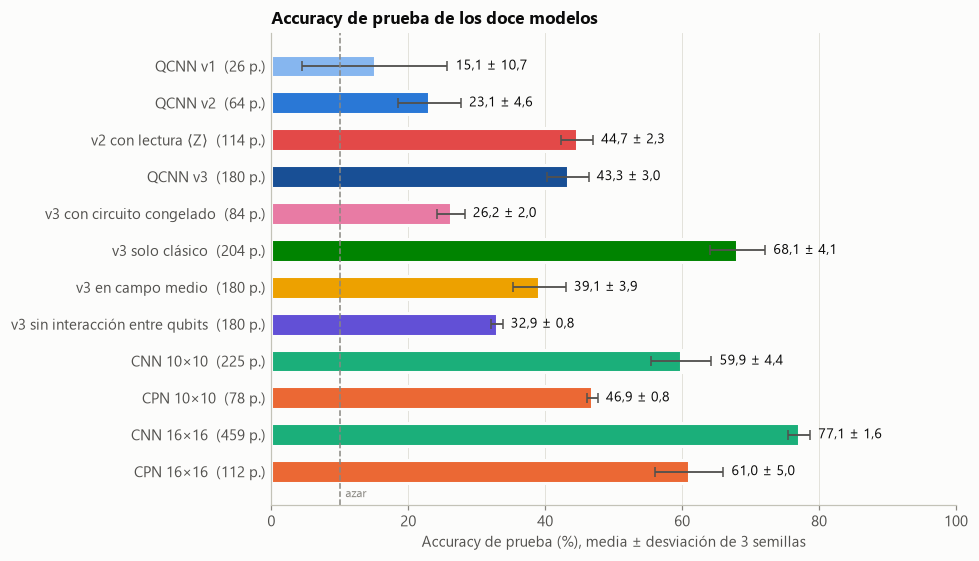

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.2))
figuras.barras(ax, S, res.ORDEN)
ax.set_title("Accuracy de prueba de los doce modelos")
fig.tight_layout()
figuras.guardar(fig, "04_barras_todos")
plt.show()

## Ablaciones de v3

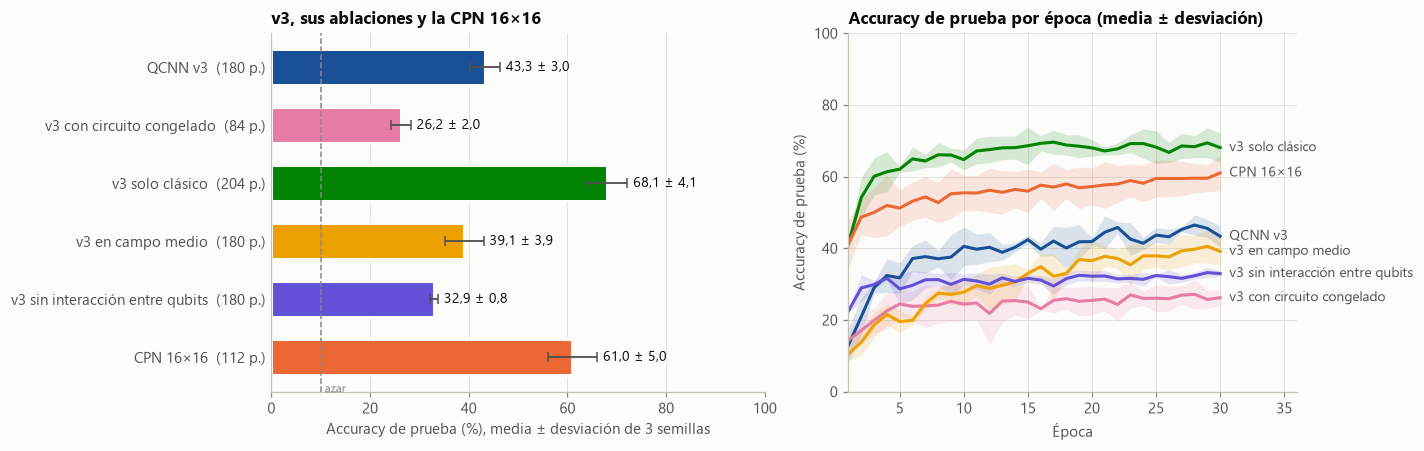

In [5]:
ablacion = ["qcnn_v3", *res.ABLACIONES]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
figuras.barras(ax1, S, ablacion)
ax1.set_title("v3, sus ablaciones y la CPN 16×16")
figuras.curvas(ax2, R, ablacion, "acc_test_por_epoca", semillas=False)
ax2.set_ylim(0, 100)
ax2.set_xlim(1, 36)
ax2.get_legend().remove()
ax2.set_title("Accuracy de prueba por época (media ± desviación)")
fig.tight_layout()
figuras.guardar(fig, "04_ablaciones")
plt.show()

Con 500 imágenes de prueba, la accuracy de una sola corrida tiene un error estándar de unos 2 puntos cerca del 50 %. Las diferencias de la tabla siguiente se comparan contra esa escala y contra la dispersión entre semillas; las menores que unos pocos puntos no se interpretan.

In [6]:
print(f"Error estándar de una accuracy del 50 % con 500 imágenes: {res.pct(res.error_estandar(0.5, 500))} puntos")
display(Markdown(res.tabla_diferencias(R, "qcnn_v3", ablacion[1:])))

Error estándar de una accuracy del 50 % con 500 imágenes: 2,2 puntos


| Modelo | Parámetros | Diferencia con QCNN v3 (puntos) | Por semilla (42 / 43 / 44) |
| --- | ---: | ---: | --- |
| v3 con circuito congelado | 84 | -17,1 | -18,8 / -18,0 / -14,6 |
| v3 solo clásico | 204 | +24,7 | +23,6 / +18,4 / +32,2 |
| v3 en campo medio | 180 | -4,2 | -6,2 / -9,6 / +3,2 |
| v3 sin interacción entre qubits | 180 | -10,4 | -11,2 / -12,8 / -7,2 |
| CPN 16×16 | 112 | +17,7 | +22,8 / +9,6 / +20,6 |

## ¿Aporta el entrelazamiento?

La ablación sin interacción pierde a la vez el entrelazamiento y el flujo de información entre parches. Comparar con ella el campo medio (flujo sin entrelazamiento) y v3 (flujo con entrelazamiento) separa las dos cosas:

In [7]:
display(Markdown(res.tabla_diferencias(R, "v3_sin_entrelazamiento", res.ENTRELAZAMIENTO)))

| Modelo | Parámetros | Diferencia con v3 sin interacción entre qubits (puntos) | Por semilla (42 / 43 / 44) |
| --- | ---: | ---: | --- |
| v3 en campo medio | 180 | +6,2 | +5,0 / +3,2 / +10,4 |
| QCNN v3 | 180 | +10,4 | +11,2 / +12,8 / +7,2 |

El campo medio mejora sobre la ablación sin interacción en las tres semillas y recupera la mayor parte de la distancia hasta v3. Lo que queda entre el campo medio y v3 es menor y cambia de signo según la semilla (tabla anterior), así que con 3 semillas y 500 imágenes de prueba no se distingue de la variación entre corridas. Además, el campo medio se simula en minutos, frente a horas para v3.

Es una aproximación de campo medio y se entrena desde cero, así que compara dos modelos, no el mismo modelo con y sin entrelazamiento. Lo que permite decir es que, en este circuito y con estos datos, lo que importa es sobre todo que la información fluya entre qubits; una contribución pequeña del entrelazamiento no se puede descartar.

## Tamaño y accuracy

El conteo de parámetros incluye todas las capas entrenables. En 10×10 la CPN tiene algo más de parámetros que v1 y v2 y las supera; v2 con lectura ⟨Z⟩, con más parámetros que la CPN, queda a su altura sin superarla. En 16×16 la CPN tiene menos parámetros que v3 y sus ablaciones y las supera a todas. La diferencia no se explica por el tamaño.

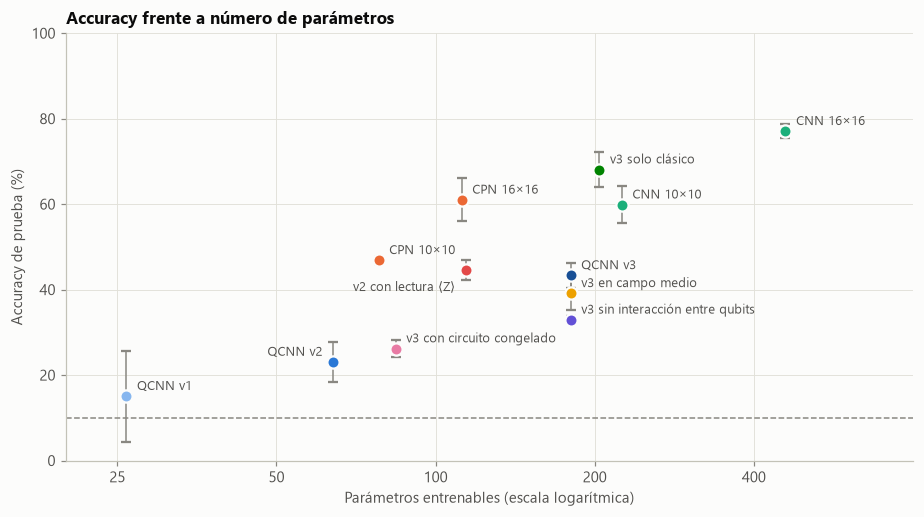

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
# Desplazamiento de la etiqueta (puntos) y alineación donde la posición por defecto se solapa.
posicion = {"qcnn_v2": ((-7, 4), "right"), "v2_lectura_z": ((-7, -14), "right")}
for m in res.ORDEN:
    r = S[m]
    ax.errorbar(
        r.n_parametros, 100 * r.acc_test_media, yerr=100 * r.acc_test_desv, fmt="o", markersize=8,
        color=figuras.COLORES[m], ecolor=figuras.TINTA_TENUE, elinewidth=1, capsize=3,
        markeredgecolor=figuras.SUPERFICIE, markeredgewidth=1.5,
    )
    desplazamiento, alineacion = posicion.get(m, ((7, 4), "left"))
    ax.annotate(
        r.nombre, (r.n_parametros, 100 * r.acc_test_media), xytext=desplazamiento, textcoords="offset points",
        ha=alineacion, fontsize=8.5, color=figuras.TINTA_SECUNDARIA,
    )
ax.set_xscale("log")
ax.set_xticks([25, 50, 100, 200, 400], ["25", "50", "100", "200", "400"])
ax.minorticks_off()
ax.set_xlim(20, 800)
ax.set_xlabel("Parámetros entrenables (escala logarítmica)")
ax.set_ylabel("Accuracy de prueba (%)")
ax.set_ylim(0, 100)
ax.axhline(100 * figuras.AZAR, color=figuras.TINTA_TENUE, linestyle="--", linewidth=1)
ax.set_title("Accuracy frente a número de parámetros")
fig.tight_layout()
figuras.guardar(fig, "04_parametros_accuracy")
plt.show()

## Conclusiones

1. **Entrenar el circuito aporta.** Con el circuito congelado en valores aleatorios, v3 pierde gran parte de su accuracy aunque conserve las capas clásicas entrenables. El circuito entrenado no es un adorno entre dos capas clásicas.
2. **La interacción entre qubits es lo que junta la información de la imagen.** Sin compuertas de dos qubits, el modelo solo ve 4 de los 16 parches y la accuracy cae.
3. **El entrelazamiento aporta poco o nada medible.** La simulación de campo medio, que conserva el flujo de información sin correlaciones cuánticas, queda cerca de v3 y por encima de la ablación sin interacción. La diferencia restante con v3 no es consistente entre semillas.
4. **Los controles clásicos ganan.** La CPN 16×16, con la misma compresión a 4 valores antes de la capa lineal y menos parámetros, supera a v3. La versión solo clásica obtiene todavía más, pero su capa lineal recibe 16 valores en lugar de 4: su ventaja mezcla la ausencia de circuito con tener cuatro veces más información a la entrada de la clasificación. Lo que sí muestra es que la capa de entrada ya extrae rasgos útiles por sí sola y que comprimirlos a 4 valores, con o sin circuito, cuesta accuracy.
5. **En este montaje no hay ventaja cuántica.** La QCNN aprende cuando la lectura lo permite (notebook 03), y su circuito contribuye frente a uno aleatorio, pero esa contribución se reproduce casi entera sin entrelazamiento, no supera a modelos clásicos de tamaño parecido y cuesta horas de simulación frente a segundos.

## Limitaciones

- 2.000 imágenes de entrenamiento y 500 de prueba; 3 semillas por modelo.
- Los mismos hiperparámetros para todos, sin ajuste por modelo; la pérdida de v3 todavía bajaba en la época 30.
- Simulación exacta sin ruido. En hardware real, el ruido y el muestreo finito de las mediciones solo podrían empeorar la parte cuántica.
- La ablación de lectura se hace sobre v2 (notebook 03); no se probó v3 con la lectura por probabilidades.
- El campo medio es una aproximación posible entre varias y se entrena desde cero; con 3 semillas, una contribución pequeña del entrelazamiento no se puede descartar.